In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("1-duty.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [7]:
for i in df.columns:
    print(df[i].value_counts())

customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
             ..
9796-MVYXX    1
2637-FKFSY    1
1552-AAGRX    1
4304-TSPVK    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64
gender
Male      3555
Female    3488
Name: count, dtype: int64
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
Partner
No     3641
Yes    3402
Name: count, dtype: int64
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineSecurity
No                     3498
Yes                    2019
No internet service    15

In [8]:
object_list = ["Partner","Dependents","PhoneService","PaperlessBilling","Churn"]
for i in object_list:
    df[i] = df[i].map({"No":0, "Yes":1})

In [9]:
other_object_list = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                    "StreamingMovies"]
for i in other_object_list:
    df[i] = df[i].map({"No":0, "Yes":1, "No internet service":0})

In [10]:
df["gender"] = df["gender"].map({"Male":0,"Female":1})
df["MultipleLines"] = df["MultipleLines"].map({"No":0,"Yes":1,"No phone service":0})

In [11]:
df.select_dtypes(include=['object']).columns.tolist()

['customerID', 'InternetService', 'Contract', 'PaymentMethod', 'TotalCharges']

In [12]:
df["TotalCharges"].unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      shape=(6531,), dtype=object)

In [13]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [14]:
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

In [15]:
df.drop("customerID",axis = 1,inplace = True)

In [16]:
X = df.drop("Churn",axis = 1)
y = df["Churn"]

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = ["InternetService","Contract","PaymentMethod"]

preprocessor = ColumnTransformer([
    ("cat",OneHotEncoder(drop="first",handle_unknown="ignore",),categorical_cols)
], remainder="passthrough")

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [19]:
import torch

X_train = torch.tensor(X_train, dtype = torch.float32)
X_test = torch.tensor(X_test, dtype = torch.float32)

y_train = torch.tensor(y_train.values, dtype = torch.float32).unsqueeze(1)
y_test = torch.tensor(y_test.values, dtype = torch.float32).unsqueeze(1)

In [20]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([4930, 23]) torch.Size([4930, 1])
torch.Size([2113, 23]) torch.Size([2113, 1])


In [21]:
def calculate_accuracy(y_test,y_pred):
    correct = torch.eq(y_test,y_pred).sum().item()
    accuracy = (correct / len(y_pred)) * 100
    return accuracy

In [22]:
from torch import nn

class ClassificationModule(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(in_features=23, out_features=64, bias=True)
        self.layer2 = nn.Linear(in_features=64, out_features=32, bias=True)
        self.layer3 = nn.Linear(in_features=32,out_features=16, bias = True)
        self.layer4 = nn.Linear(in_features=16, out_features=1,bias=True)

        self.relu = nn.ReLU()

    def forward(self, x:torch.Tensor) -> torch.Tensor:
        return(self.layer4(self.relu(self.layer3(self.relu(self.layer2(self.relu(self.layer1(x))))))))

In [23]:
model = ClassificationModule()

In [24]:
model

ClassificationModule(
  (layer1): Linear(in_features=23, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (layer3): Linear(in_features=32, out_features=16, bias=True)
  (layer4): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
)

In [25]:
negative = (y_train == 0).sum().item()
pozitive = (y_train == 1).sum().item()

calculated_weight = negative / pozitive
print(calculated_weight)

2.7691131498470947


In [26]:
weight = torch.tensor([calculated_weight], dtype=torch.float32)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=weight)
optimizer = torch.optim.Adam(params = model.parameters(),lr = 0.001, weight_decay=1e-4)

In [27]:
import copy
best_test_loss = float("inf")
patience = 15
patience_counter = 0
best_state = None

torch.manual_seed(42)
epochs = 200
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []


for epoch in range(epochs):
    model.train()

    y_logits = model(X_train)
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits,y_train)
    acc = calculate_accuracy(y_train,y_pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())
    train_accuracies.append(acc)


    model.eval()

    with torch.inference_mode():
        test_logits = model(X_test)
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits,y_test)
        test_acc = calculate_accuracy(y_test,test_pred)

    test_losses.append(test_loss.item())
    test_accuracies.append(test_acc)

    if test_loss.item() < best_test_loss:
        best_test_loss = test_loss.item()
        patience_counter = 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping: epoch {epoch}")
            break

    if epoch % 5 == 0:
         print(f"Epoch: {epoch}, Loss: {loss}, Accuracy: {acc}, Test Loss: {test_loss}, Test Accuracy = {test_acc}")
        
model.load_state_dict(best_state)

Epoch: 0, Loss: 1.0149016380310059, Accuracy: 73.4685598377282, Test Loss: 1.0122119188308716, Test Accuracy = 73.450070989115
Epoch: 5, Loss: 0.9986720085144043, Accuracy: 73.4685598377282, Test Loss: 0.9966917037963867, Test Accuracy = 73.450070989115
Epoch: 10, Loss: 0.9811281561851501, Accuracy: 74.0973630831643, Test Loss: 0.9791863560676575, Test Accuracy = 74.39659252247989
Epoch: 15, Loss: 0.9595606923103333, Accuracy: 78.58012170385396, Test Loss: 0.957389235496521, Test Accuracy = 77.520113582584
Epoch: 20, Loss: 0.9327310919761658, Accuracy: 78.78296146044624, Test Loss: 0.9301417469978333, Test Accuracy = 77.85139611926172
Epoch: 25, Loss: 0.899940550327301, Accuracy: 78.76267748478702, Test Loss: 0.8969983458518982, Test Accuracy = 77.520113582584
Epoch: 30, Loss: 0.8622714877128601, Accuracy: 77.8498985801217, Test Loss: 0.8596441149711609, Test Accuracy = 77.04685281590156
Epoch: 35, Loss: 0.8236538171768188, Accuracy: 76.63286004056795, Test Loss: 0.8233362436294556, Te

<All keys matched successfully>

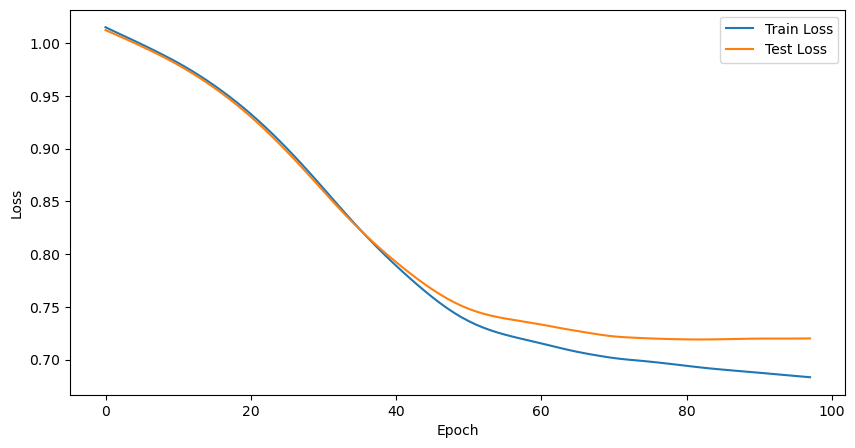

In [28]:
plt.figure(figsize = (10,5))
plt.plot(train_losses,label = "Train Loss")
plt.plot(test_losses,label = "Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

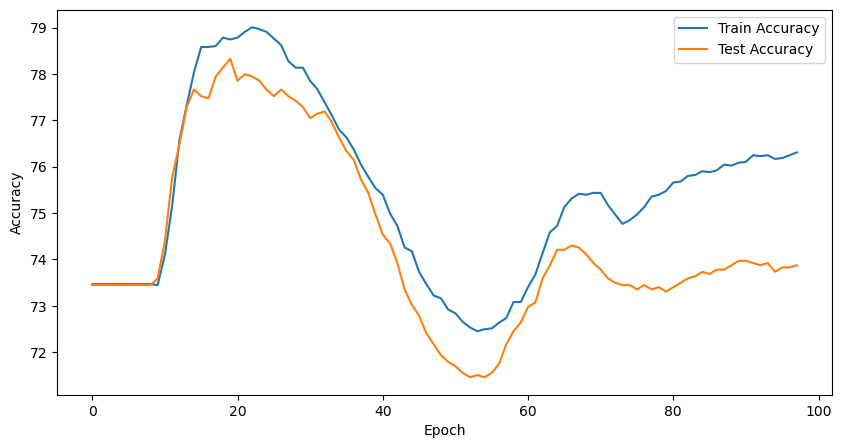

In [29]:
plt.figure(figsize = (10,5))
plt.plot(train_accuracies,label = "Train Accuracy")
plt.plot(test_accuracies,label = "Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [30]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,0,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,1,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


In [31]:
new_sample = np.array([[1,0,1,0,1,0,0,"DSL",0,1,0,0,0,0,"Month-to-month",1,	"Electronic check",29.85,29.85]])

In [32]:
new_sample_df = pd.DataFrame(new_sample, columns=X.columns)
new_sample_processed = preprocessor.transform(new_sample_df)

if hasattr(new_sample_processed, "toarray"):
    new_sample_processed = new_sample_processed.toarray()

new_sample_processed = new_sample_processed.astype(float)
    
new_sample_scaler = scaler.transform(new_sample_processed)

new_sample_tensor = torch.tensor(new_sample_scaler, dtype=torch.float32)

In [33]:
model.eval()
with torch.inference_mode():
    logits = model(new_sample_tensor)
    predicted_class = torch.round(torch.sigmoid(logits)).item() 

In [34]:
print(predicted_class)

1.0


In [35]:
from torchmetrics.classification import ConfusionMatrix
cm = ConfusionMatrix(task = "binary")

In [36]:
matrix = cm(test_pred,y_test)
print(matrix)

tensor([[1115,  437],
        [ 115,  446]])


In [37]:
from sklearn.metrics import f1_score, recall_score, precision_score
print("F1 Score:", f1_score(y_test.numpy(), test_pred.detach().numpy()))
print("Recall Score:", recall_score(y_test.numpy(),test_pred.detach().numpy()))
print("Precision_score:" ,precision_score(y_test.numpy(),test_pred.detach().numpy()))

F1 Score: 0.6177285318559557
Recall Score: 0.7950089126559715
Precision_score: 0.5050962627406569


In [38]:
from torchmetrics.utilities.plot import plot_confusion_matrix

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

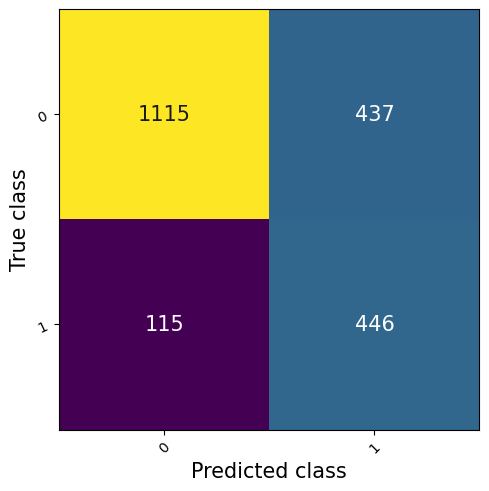

In [39]:
plot_confusion_matrix(matrix)

In [40]:
from pathlib import Path
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "telco_churn_classification_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

torch.save(obj=model.state_dict(),f = MODEL_SAVE_PATH)

In [41]:
model.state_dict()

OrderedDict([('layer1.weight',
              tensor([[ 0.1457,  0.1115, -0.0057,  ...,  0.1978, -0.0300, -0.2211],
                      [ 0.1610,  0.0748, -0.1402,  ..., -0.1093, -0.0234, -0.1300],
                      [-0.1017, -0.0982,  0.0357,  ...,  0.1745, -0.1139, -0.1673],
                      ...,
                      [-0.0002,  0.2267,  0.1430,  ...,  0.1094, -0.1315,  0.0387],
                      [-0.1903,  0.0149,  0.0722,  ...,  0.1493, -0.1737, -0.0056],
                      [-0.0811,  0.0110, -0.0409,  ..., -0.0513, -0.1450,  0.1582]])),
             ('layer1.bias',
              tensor([ 0.1994,  0.2027,  0.0986, -0.0811,  0.2255,  0.1731, -0.0336,  0.0312,
                       0.0349,  0.0307, -0.2035, -0.1480,  0.0849,  0.1534, -0.0506,  0.0054,
                      -0.1969, -0.1606,  0.1450,  0.0653,  0.2370,  0.1680, -0.0248, -0.0985,
                       0.1830,  0.0966, -0.0811,  0.0254,  0.2269, -0.0582,  0.1295,  0.0611,
                      -0.0266,

In [42]:
loaded_model = ClassificationModule()

In [43]:
type(torch.load(MODEL_SAVE_PATH))

collections.OrderedDict

In [44]:
loaded_model.load_state_dict(torch.load(MODEL_SAVE_PATH))

<All keys matched successfully>

In [45]:
print(type(preprocessor))
print(type(scaler))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'sklearn.preprocessing._data.StandardScaler'>


In [46]:
import joblib
joblib.dump(preprocessor, "models/preprocessor.joblib")
joblib.dump(scaler, "models/scaler.joblib")

['models/scaler.joblib']

In [47]:
import os
print(os.listdir("models"))

['iris_classification_model.pth', 'preprocessor.joblib', 'scaler.joblib', 'telco_churn_classification_model.pth']


In [48]:
loaded_preprocessor = joblib.load("models/preprocessor.joblib")
loaded_scaler = joblib.load("models/scaler.joblib")

In [49]:
print(type(loaded_preprocessor))
print(type(loaded_scaler))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'sklearn.preprocessing._data.StandardScaler'>


In [50]:
print(X.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [51]:
print(type(X))
print(X.shape)

<class 'pandas.core.frame.DataFrame'>
(7043, 19)


In [52]:
sample = X.iloc[[0]]
print(sample)

   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       1              0        1           0       1             0   

   MultipleLines InternetService  OnlineSecurity  OnlineBackup  \
0              0             DSL               0             1   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  \
0                 0            0            0                0   

         Contract  PaperlessBilling     PaymentMethod  MonthlyCharges  \
0  Month-to-month                 1  Electronic check           29.85   

   TotalCharges  
0         29.85  


In [53]:
sample_processed = loaded_preprocessor.transform(sample)

In [54]:
sample_scaled =loaded_scaler.transform(sample_processed)

In [55]:
print(sample_scaled.shape)

(1, 23)


In [56]:
print(y.iloc[0])

0


In [57]:
sample_tensor = torch.tensor(sample_scaled, dtype=torch.float32)
loaded_model.eval()
with torch.no_grad():
    logit = loaded_model(sample_tensor)
    prob = torch.round(torch.sigmoid(logit))
print(prob.item())

1.0


In [58]:
sample_tensor = torch.tensor(sample_scaled, dtype=torch.float32)
loaded_model.eval()
with torch.no_grad():
    logit = loaded_model(sample_tensor)
    prob = torch.sigmoid(logit)
print(prob.item())

0.7404528260231018


In [59]:
sample_tensor = torch.tensor(sample_scaled, dtype=torch.float32)
model.eval()
with torch.no_grad():
    logit = model(sample_tensor)
    prob = torch.sigmoid(logit)
print(prob.item())

0.7404528260231018
